In [46]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [47]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [48]:
data=pd.read_excel('/content/drive/MyDrive/flight_customer_data.xlsx')

In [49]:
data.shape

(11760, 17)

In [50]:
data.head()

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
0,1000001,Yes,307.0,iOS and Android,38570.0,1,2,Financial,94.0,5993,8,Yes,11,No,1,0,8
1,1000002,No,367.0,iOS,9765.0,1,1,Financial,61.0,5130,1,No,23,Yes,4,1,10
2,1000003,Yes,277.0,iOS and Android,48055.0,1,2,Other,92.0,2090,6,Yes,15,No,2,0,7
3,1000004,No,247.0,iOS,48720.0,1,4,Financial,56.0,2909,1,Yes,11,No,3,0,8
4,1000005,No,202.0,iOS and Android,20685.0,1,1,Medical,40.0,3468,9,No,12,No,4,1,6


In [51]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11760 entries, 0 to 11759
Data columns (total 17 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   UserID                                        11760 non-null  int64  
 1   Taken_product                                 11760 non-null  object 
 2   Yearly_avg_view_on_travel_page                11179 non-null  float64
 3   preferred_device                              11707 non-null  object 
 4   total_likes_on_outstation_checkin_given       11379 non-null  float64
 5   yearly_avg_Outstation_checkins                11685 non-null  object 
 6   member_in_family                              11760 non-null  object 
 7   preferred_location_type                       11729 non-null  object 
 8   Yearly_avg_comment_on_travel_page             11554 non-null  float64
 9   total_likes_on_outofstation_checkin_received  11760 non-null 

In [52]:
for col in ['yearly_avg_Outstation_checkins', 'member_in_family']:
    print(data[col].value_counts(dropna=False))

yearly_avg_Outstation_checkins
1      4543
2       844
10      682
9       340
3       336
7       336
8       320
5       261
4       256
16      255
6       236
11      229
24      223
23      215
29      215
18      208
15      206
20      199
26      199
25      198
28      180
19      176
14      167
17      160
12      159
22      152
13      150
21      143
27       96
NaN      75
*         1
Name: count, dtype: int64
member_in_family
3        4561
4        3184
2        2256
1        1349
5         384
Three      15
10         11
Name: count, dtype: int64


In [53]:
data['yearly_avg_Outstation_checkins'] = pd.to_numeric(
    data['yearly_avg_Outstation_checkins'].replace('*', np.nan))

data['member_in_family'] = pd.to_numeric(
    data['member_in_family'].replace('Three', 3))

/tmp/ipykernel_1200/106051489.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['yearly_avg_Outstation_checkins'].replace('*', np.nan))
/tmp/ipykernel_1200/106051489.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['member_in_family'].replace('Three', 3))


In [54]:
print(data['following_company_page'].value_counts(dropna=False))

following_company_page
No     8355
Yes    3285
NaN     103
1        12
0         5
Name: count, dtype: int64


In [55]:
data['following_company_page'] = data['following_company_page'].replace(
    {1: 'Yes', 0: 'No', '1': 'Yes', '0': 'No'})

print(data['following_company_page'].value_counts(dropna=False))

following_company_page
No     8360
Yes    3297
NaN     103
Name: count, dtype: int64


In [56]:
print(data['preferred_device'].value_counts(dropna=False))

preferred_device
Tab                4172
iOS and Android    4134
Laptop             1108
iOS                1095
Mobile              600
Android             315
Android OS          145
ANDROID             134
NaN                  53
Other                 2
Others                2
Name: count, dtype: int64


In [57]:
data['preferred_device'] = data['preferred_device'].replace({
    'Tab': 'Mobile',
    'iOS and Android': 'Mobile',
    'iOS': 'Mobile',
    'Mobile': 'Mobile',
    'Android': 'Mobile',
    'Android OS': 'Mobile',
    'ANDROID': 'Mobile',
    'Other': np.nan,
    'Others': np.nan})

print(data['preferred_device'].value_counts(dropna=False))

preferred_device
Mobile    10595
Laptop     1108
NaN          57
Name: count, dtype: int64


In [58]:
print(data['preferred_location_type'].value_counts(dropna=False))

preferred_location_type
Beach              2424
Financial          2409
Historical site    1856
Medical            1845
Other               643
Big Cities          636
Social media        633
Trekking            528
Entertainment       516
Hill Stations       108
Tour  Travel         60
Tour and Travel      47
NaN                  31
Game                 12
OTT                   7
Movie                 5
Name: count, dtype: int64


In [59]:
data['preferred_location_type'] = data['preferred_location_type'].replace({
    'Tour  Travel': 'Tour and Travel',
    'Game': 'Entertainment',
    'Movie': 'Entertainment',
    'OTT': 'Entertainment'})

print(data['preferred_location_type'].value_counts(dropna=False))

preferred_location_type
Beach              2424
Financial          2409
Historical site    1856
Medical            1845
Other               643
Big Cities          636
Social media        633
Entertainment       540
Trekking            528
Hill Stations       108
Tour and Travel     107
NaN                  31
Name: count, dtype: int64


In [60]:
data['Adult_flag'].value_counts(dropna=False)

,count
Adult_flag,
0,5048
1,4768
2,1264
3,680


In [61]:
data['Adult_flag'] = data['Adult_flag'].replace({2: 1, 3: 1})

print(data['Adult_flag'].value_counts().sort_index())

Adult_flag
0    5048
1    6712
Name: count, dtype: int64


In [62]:
x = data.drop(columns='UserID')

data = data[~x.duplicated()].reset_index(drop=True)

print(data.shape)
print(data.drop(columns='UserID').duplicated().sum())
print(data['preferred_device'].value_counts(dropna=False))

(10621, 17)
0
preferred_device
Mobile    9456
Laptop    1108
NaN         57
Name: count, dtype: int64


In [63]:
missing = data.isnull().sum()
missing = missing[missing > 0]

pd.DataFrame({'Missing': missing,
              'Percent': (missing / len(data) * 100).round(2)}) \
  .sort_values('Missing', ascending=False)

,Missing,Percent
Yearly_avg_view_on_travel_page,467,4.40
total_likes_on_outstation_checkin_given,312,2.94
Yearly_avg_comment_on_travel_page,206,1.94
following_company_page,103,0.97
yearly_avg_Outstation_checkins,76,0.72
preferred_device,57,0.54
preferred_location_type,31,0.29


In [64]:
data.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
UserID,10621.0,1006272.3,3340.3,1000001.0,1003795.0,1006450.0,1009105.0,1011760.0
Yearly_avg_view_on_travel_page,10154.0,281.7,68.6,35.0,232.0,272.0,326.0,464.0
total_likes_on_outstation_checkin_given,10309.0,28190.2,14417.6,3570.0,16382.0,28105.0,40536.0,252430.0
yearly_avg_Outstation_checkins,10545.0,8.3,8.6,1.0,1.0,5.0,14.0,29.0
member_in_family,10621.0,2.9,1.0,1.0,2.0,3.0,4.0,10.0
Yearly_avg_comment_on_travel_page,10415.0,75.8,24.1,3.0,58.0,76.0,93.0,815.0
total_likes_on_outofstation_checkin_received,10621.0,6538.0,4708.1,1009.0,2943.0,4955.0,8408.0,20065.0
week_since_last_outstation_checkin,10621.0,3.3,2.6,0.0,1.0,3.0,5.0,11.0
montly_avg_comment_on_company_page,10621.0,30.1,51.0,11.0,18.0,23.0,28.0,500.0
travelling_network_rating,10621.0,2.7,1.1,1.0,2.0,3.0,4.0,4.0


In [65]:
print(data['Taken_product'].value_counts())
print(data['Taken_product'].value_counts(normalize=True).round(2))

Taken_product
No     8906
Yes    1715
Name: count, dtype: int64
Taken_product
No     0.84
Yes    0.16
Name: proportion, dtype: float64


In [66]:
print(data['preferred_device'].value_counts(dropna=False))
print(pd.crosstab(data['preferred_device'], data['Taken_product']))

preferred_device
Mobile    9456
Laptop    1108
NaN         57
Name: count, dtype: int64
Taken_product       No   Yes
preferred_device            
Laptop             832   276
Mobile            8028  1428


Univariate Analysis


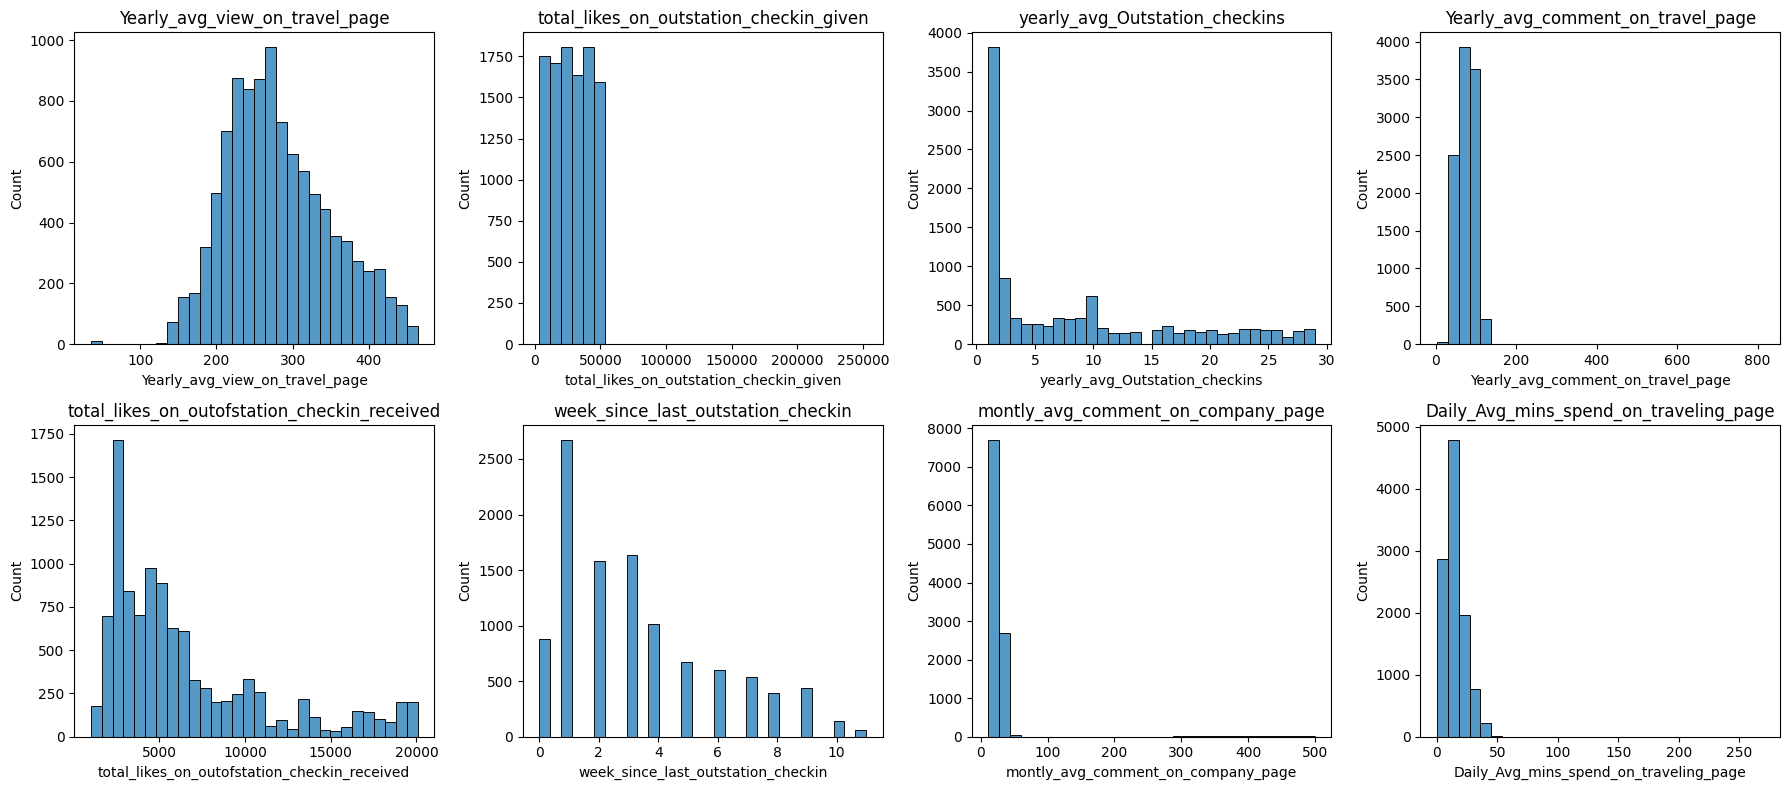

In [67]:
num_cols = ['Yearly_avg_view_on_travel_page',
            'total_likes_on_outstation_checkin_given',
            'yearly_avg_Outstation_checkins',
            'Yearly_avg_comment_on_travel_page',
            'total_likes_on_outofstation_checkin_received',
            'week_since_last_outstation_checkin',
            'montly_avg_comment_on_company_page',
            'Daily_Avg_mins_spend_on_traveling_page']


plt.figure(figsize=(18, 8))

for i, col in enumerate(num_cols):
    plt.subplot(2, 4, i+1)
    sns.histplot(data[col].dropna(), bins=30)
    plt.title(col)

plt.tight_layout()
plt.show()

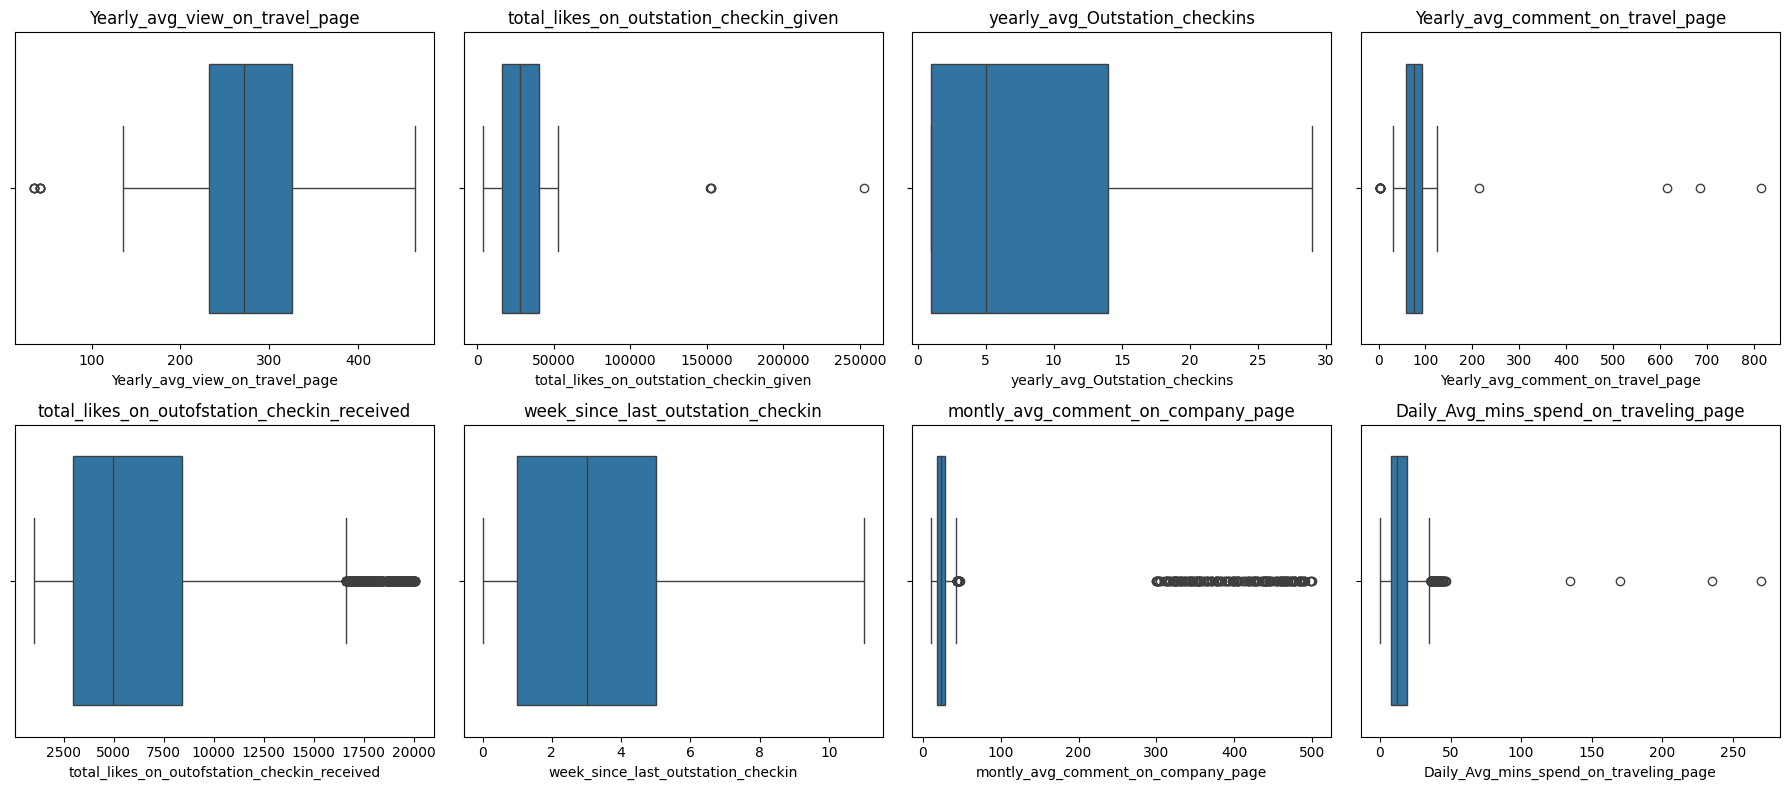

In [68]:
plt.figure(figsize=(18, 8))

for i, col in enumerate(num_cols):
    plt.subplot(2, 4, i+1)
    sns.boxplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [69]:
rows = []
for col in num_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)).sum()
    rows.append([col, round(data[col].skew(), 2), n_out])

pd.DataFrame(rows, columns=['Variable', 'Skewness', 'Outliers (IQR)'])

,Variable,Skewness,Outliers (IQR)
0,Yearly_avg_view_on_travel_page,0.40,9
1,total_likes_on_outstation_checkin_given,0.54,4
2,yearly_avg_Outstation_checkins,0.96,0
3,Yearly_avg_comment_on_travel_page,5.34,25
4,total_likes_on_outofstation_checkin_received,1.37,819
5,week_since_last_outstation_checkin,0.91,0
6,montly_avg_comment_on_company_page,7.32,226
7,Daily_Avg_mins_spend_on_traveling_page,4.72,232


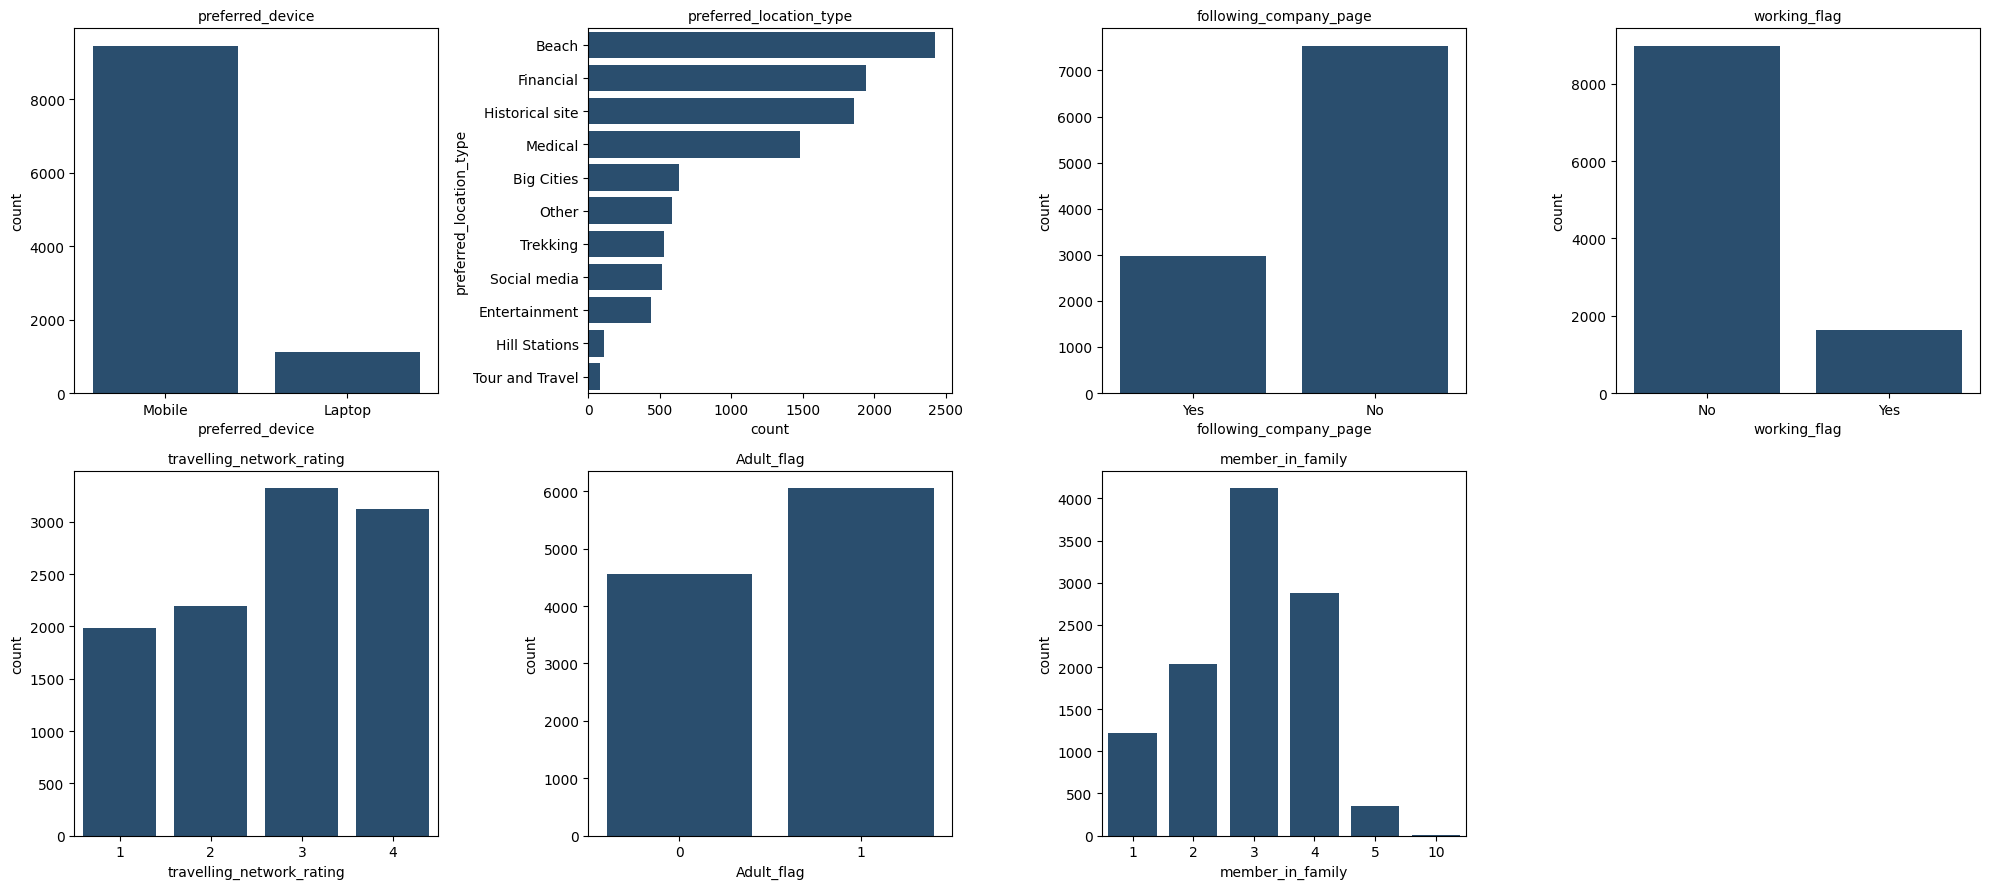

In [70]:
cat_cols = ['preferred_device', 'preferred_location_type',
            'following_company_page', 'working_flag',
            'travelling_network_rating', 'Adult_flag', 'member_in_family']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    order = data[col].value_counts().index
    if col == 'preferred_location_type':
        sns.countplot(y=data[col], order=order, color='#1f4e79', ax=ax)
    else:
        sns.countplot(x=data[col], color='#1f4e79', ax=ax)
    ax.set_title(col, fontsize=10)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

In [71]:
for col in cat_cols:
    print('-----', col)
    print((data[col].value_counts(normalize=True) * 100).round(1))

----- preferred_device
preferred_device
Mobile    89.5
Laptop    10.5
Name: proportion, dtype: float64
----- preferred_location_type
preferred_location_type
Beach              22.9
Financial          18.3
Historical site    17.5
Medical            14.0
Big Cities          6.0
Other               5.5
Trekking            5.0
Social media        4.9
Entertainment       4.1
Hill Stations       1.0
Tour and Travel     0.8
Name: proportion, dtype: float64
----- following_company_page
following_company_page
No     71.7
Yes    28.3
Name: proportion, dtype: float64
----- working_flag
working_flag
No     84.6
Yes    15.4
Name: proportion, dtype: float64
----- travelling_network_rating
travelling_network_rating
3    31.3
4    29.4
2    20.7
1    18.7
Name: proportion, dtype: float64
----- Adult_flag
Adult_flag
1    57.0
0    43.0
Name: proportion, dtype: float64
----- member_in_family
member_in_family
3     38.8
4     27.1
2     19.2
1     11.5
5      3.3
10     0.1
Name: proportion, dtype: float

Bivariate Analysis


In [72]:
data['target'] = (data['Taken_product'] == 'Yes').astype(int)

overall = data['target'].mean() * 100
print('Overall purchase rate: %.1f%%' % overall)

Overall purchase rate: 16.1%


In [73]:
cat_cols = ['preferred_device', 'following_company_page', 'Adult_flag',
            'working_flag', 'travelling_network_rating',
            'member_in_family', 'preferred_location_type']

for col in cat_cols:
    t = data.groupby(col)['target'].agg(['mean', 'count'])
    t['mean'] = (t['mean'] * 100).round(1)
    print('-----', col)
    print(t.rename(columns={'mean': 'purchase_rate_%', 'count': 'customers'}))

----- preferred_device
                  purchase_rate_%  customers
preferred_device                            
Laptop                       24.9       1108
Mobile                       15.1       9456
----- following_company_page
                        purchase_rate_%  customers
following_company_page                            
No                                 10.5       7537
Yes                                30.5       2981
----- Adult_flag
            purchase_rate_%  customers
Adult_flag                            
0                      24.5       4565
1                       9.8       6056
----- working_flag
              purchase_rate_%  customers
working_flag                            
No                       16.1       8985
Yes                      16.3       1636
----- travelling_network_rating
                           purchase_rate_%  customers
travelling_network_rating                            
1                                     20.7       1985
2             

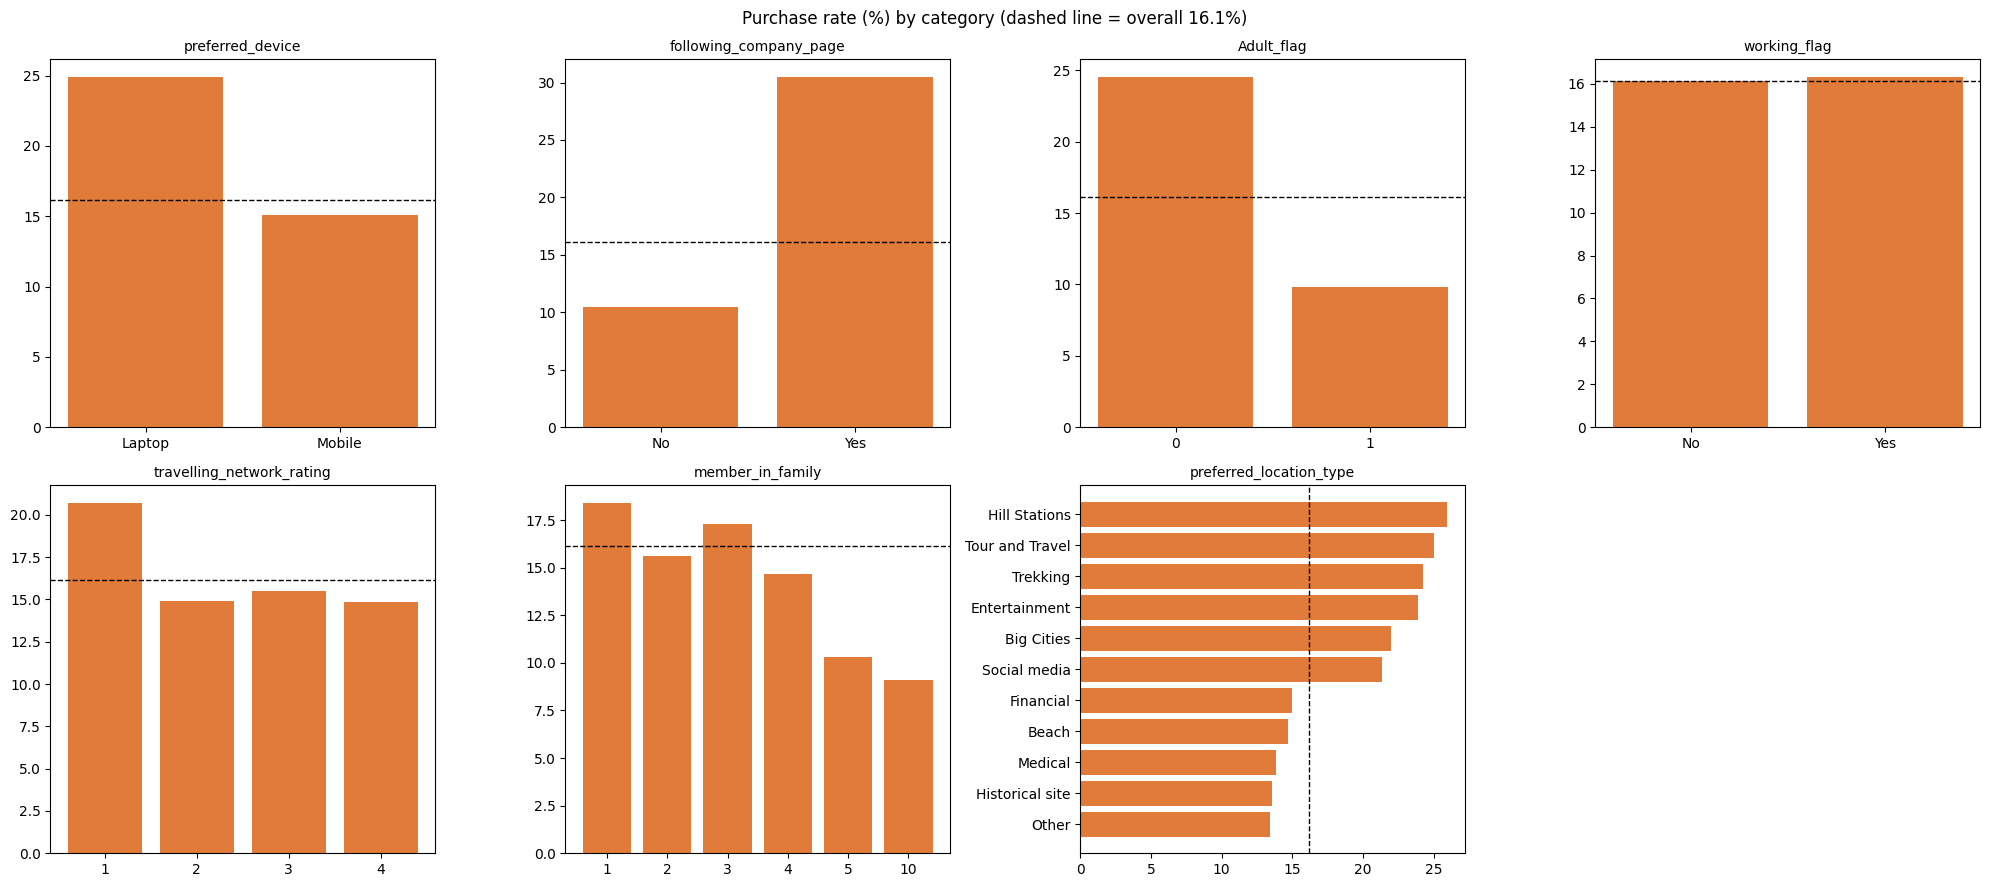

In [74]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = data.groupby(col)['target'].mean() * 100
    if col == 'preferred_location_type':
        rate = rate.sort_values()
        ax.barh(rate.index, rate.values, color='#e07b39')
        ax.axvline(overall, color='black', ls='--', lw=1)
    else:
        ax.bar(rate.index.astype(str), rate.values, color='#e07b39')
        ax.axhline(overall, color='black', ls='--', lw=1)
    ax.set_title(col, fontsize=10)
axes.ravel()[-1].axis('off')
plt.suptitle('Purchase rate (%) by category (dashed line = overall 16.1%)')
plt.tight_layout()
plt.show()

In [75]:
num_cols = ['Yearly_avg_view_on_travel_page',
            'total_likes_on_outstation_checkin_given',
            'yearly_avg_Outstation_checkins',
            'Yearly_avg_comment_on_travel_page',
            'total_likes_on_outofstation_checkin_received',
            'week_since_last_outstation_checkin',
            'montly_avg_comment_on_company_page',
            'Daily_Avg_mins_spend_on_traveling_page']

data.groupby('Taken_product')[num_cols].median().T

Taken_product,No,Yes
Yearly_avg_view_on_travel_page,277.0,243.0
total_likes_on_outstation_checkin_given,28630.0,24468.0
yearly_avg_Outstation_checkins,4.0,8.0
Yearly_avg_comment_on_travel_page,76.0,75.0
total_likes_on_outofstation_checkin_received,5229.5,3229.0
week_since_last_outstation_checkin,3.0,3.0
montly_avg_comment_on_company_page,23.0,23.0
Daily_Avg_mins_spend_on_traveling_page,13.0,10.0


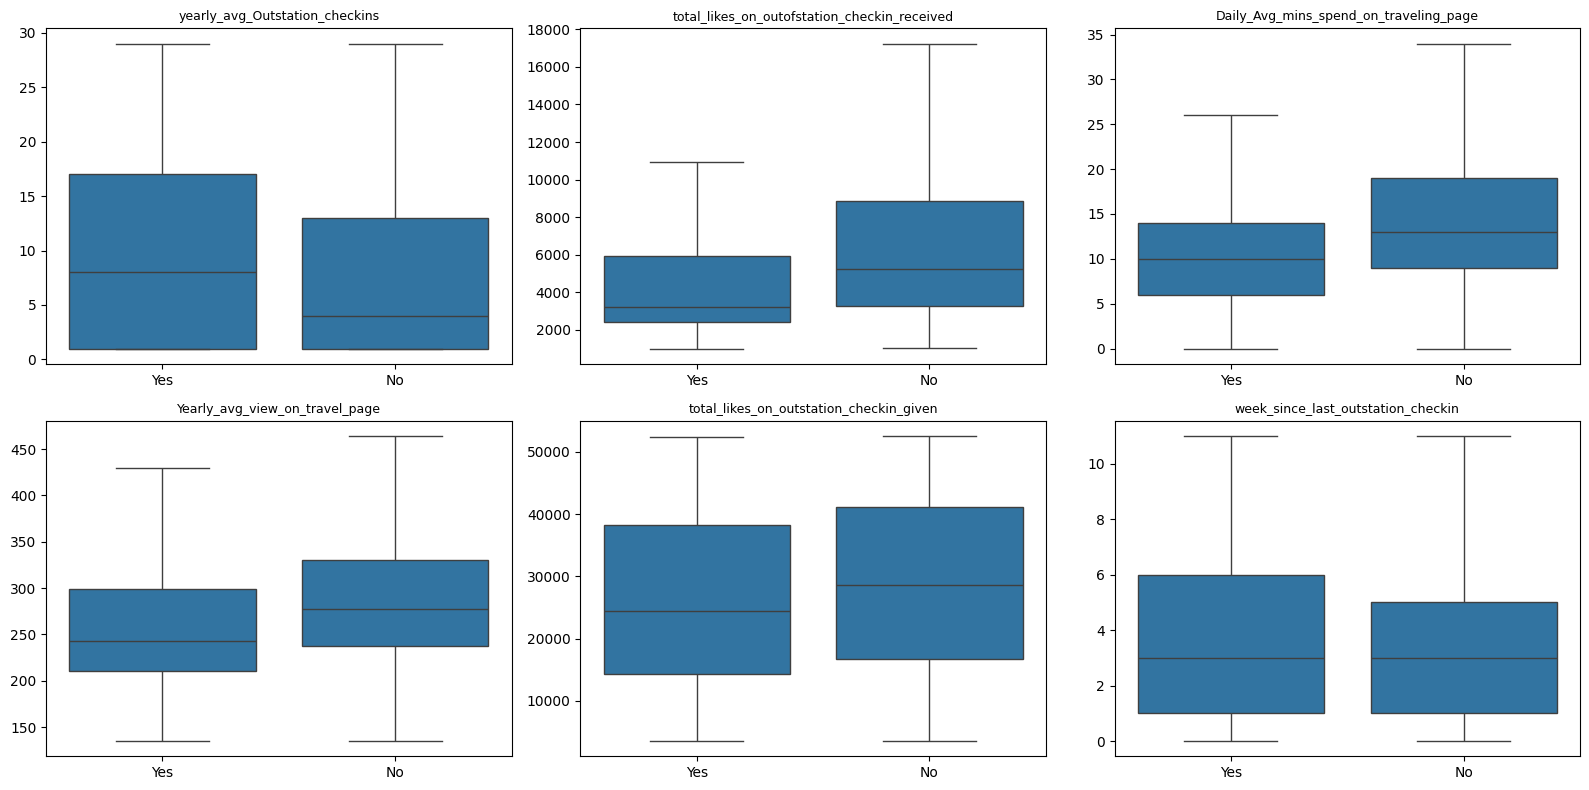

In [76]:
sel = ['yearly_avg_Outstation_checkins',
       'total_likes_on_outofstation_checkin_received',
       'Daily_Avg_mins_spend_on_traveling_page',
       'Yearly_avg_view_on_travel_page',
       'total_likes_on_outstation_checkin_given',
       'week_since_last_outstation_checkin']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), sel):
    sns.boxplot(data=data, x='Taken_product', y=col, showfliers=False, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [77]:
for col in ['total_likes_on_outofstation_checkin_received',
            'Daily_Avg_mins_spend_on_traveling_page']:
    q = pd.qcut(data[col], 4, duplicates='drop')
    print('-----', col)
    print((data.groupby(q, observed=True)['target'].mean() * 100).round(1))

bins = pd.cut(data['yearly_avg_Outstation_checkins'], [0, 1, 5, 10, 20, 30])
print('----- yearly_avg_Outstation_checkins')
print((data.groupby(bins, observed=True)['target'].mean() * 100).round(1))

----- total_likes_on_outofstation_checkin_received
total_likes_on_outofstation_checkin_received
(1008.999, 2943.0]    29.6
(2943.0, 4955.0]      14.3
(4955.0, 8408.0]      10.4
(8408.0, 20065.0]     10.3
Name: target, dtype: float64
----- Daily_Avg_mins_spend_on_traveling_page
Daily_Avg_mins_spend_on_traveling_page
(-0.001, 8.0]    26.1
(8.0, 12.0]      15.0
(12.0, 19.0]     12.9
(19.0, 270.0]     9.2
Name: target, dtype: float64
----- yearly_avg_Outstation_checkins
yearly_avg_Outstation_checkins
(0, 1]      14.0
(1, 5]      14.4
(5, 10]     14.2
(10, 20]    20.0
(20, 30]    22.0
Name: target, dtype: float64


Multivariate Analysis


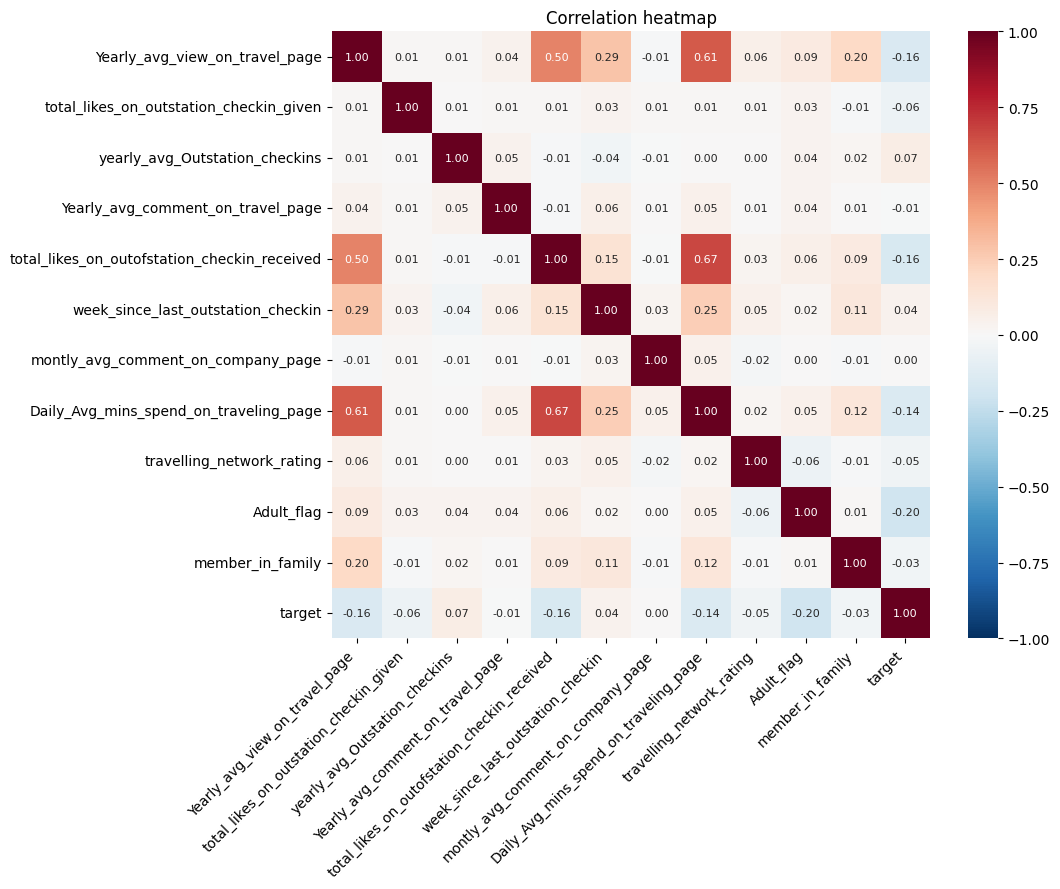

In [78]:
cols = ['Yearly_avg_view_on_travel_page',
        'total_likes_on_outstation_checkin_given',
        'yearly_avg_Outstation_checkins',
        'Yearly_avg_comment_on_travel_page',
        'total_likes_on_outofstation_checkin_received',
        'week_since_last_outstation_checkin',
        'montly_avg_comment_on_company_page',
        'Daily_Avg_mins_spend_on_traveling_page',
        'travelling_network_rating', 'Adult_flag',
        'member_in_family', 'target']

plt.figure(figsize=(11, 9))
sns.heatmap(data[cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, annot_kws={'size': 8})
plt.xticks(rotation=45, ha='right')
plt.title('Correlation heatmap')
plt.tight_layout()
plt.show()

In [79]:
print(data.pivot_table(index='preferred_device', columns='following_company_page',
                       values='target', aggfunc='mean').mul(100).round(1))

print(data.pivot_table(index='preferred_device', columns='Adult_flag',
                       values='target', aggfunc='mean').mul(100).round(1))

print(data.pivot_table(index='following_company_page', columns='Adult_flag',
                       values='target', aggfunc='mean').mul(100).round(1))

following_company_page    No   Yes
preferred_device                  
Laptop                  17.3  41.9
Mobile                   9.7  28.9
Adult_flag           0     1
preferred_device            
Laptop            34.7  17.3
Mobile            23.3   8.9
Adult_flag                 0     1
following_company_page            
No                      16.1   6.3
Yes                     45.3  18.9


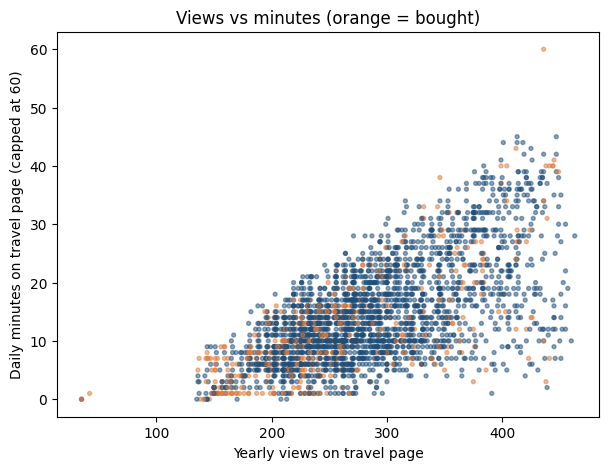

In [80]:
sample = data.sample(3000, random_state=1)
plt.figure(figsize=(7, 5))
plt.scatter(sample['Yearly_avg_view_on_travel_page'],
            sample['Daily_Avg_mins_spend_on_traveling_page'].clip(upper=60),
            c=sample['target'].map({0: '#1f4e79', 1: '#e07b39'}),
            s=8, alpha=0.5)
plt.xlabel('Yearly views on travel page')
plt.ylabel('Daily minutes on travel page (capped at 60)')
plt.title('Views vs minutes (orange = bought)')
plt.show()

In [81]:
print('Shape:', data.shape)
print('Duplicate rows (ignoring UserID):', data.drop(columns='UserID').duplicated().sum())
print('Duplicate UserIDs:', data['UserID'].duplicated().sum())

Shape: (10621, 18)
Duplicate rows (ignoring UserID): 0
Duplicate UserIDs: 0


In [82]:
data.info()

for col in ['Taken_product', 'preferred_device', 'preferred_location_type',
            'following_company_page', 'working_flag']:
    print(col, '->', data[col].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10621 entries, 0 to 10620
Data columns (total 18 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   UserID                                        10621 non-null  int64  
 1   Taken_product                                 10621 non-null  object 
 2   Yearly_avg_view_on_travel_page                10154 non-null  float64
 3   preferred_device                              10564 non-null  object 
 4   total_likes_on_outstation_checkin_given       10309 non-null  float64
 5   yearly_avg_Outstation_checkins                10545 non-null  float64
 6   member_in_family                              10621 non-null  int64  
 7   preferred_location_type                       10590 non-null  object 
 8   Yearly_avg_comment_on_travel_page             10415 non-null  float64
 9   total_likes_on_outofstation_checkin_received  10621 non-null 

In [83]:
# Count first
print('Likes given > 60000      :', (data['total_likes_on_outstation_checkin_given'] > 60000).sum())
print('Travel comments > 150    :', (data['Yearly_avg_comment_on_travel_page'] > 150).sum())
print('Daily minutes > 100      :', (data['Daily_Avg_mins_spend_on_traveling_page'] > 100).sum())
print('Yearly views < 100       :', (data['Yearly_avg_view_on_travel_page'] < 100).sum())

# Set them to missing
data.loc[data['total_likes_on_outstation_checkin_given'] > 60000,
         'total_likes_on_outstation_checkin_given'] = np.nan
data.loc[data['Yearly_avg_comment_on_travel_page'] > 150,
         'Yearly_avg_comment_on_travel_page'] = np.nan
data.loc[data['Daily_Avg_mins_spend_on_traveling_page'] > 100,
         'Daily_Avg_mins_spend_on_traveling_page'] = np.nan
data.loc[data['Yearly_avg_view_on_travel_page'] < 100,
         'Yearly_avg_view_on_travel_page'] = np.nan

Likes given > 60000      : 4
Travel comments > 150    : 4
Daily minutes > 100      : 4
Yearly views < 100       : 9


In [84]:
missing = data.isnull().sum()
missing = missing[missing > 0]

pd.DataFrame({'Missing': missing,
              'Percent': (missing / len(data) * 100).round(2)}) \
  .sort_values('Missing', ascending=False)

,Missing,Percent
Yearly_avg_view_on_travel_page,476,4.48
total_likes_on_outstation_checkin_given,316,2.98
Yearly_avg_comment_on_travel_page,210,1.98
following_company_page,103,0.97
yearly_avg_Outstation_checkins,76,0.72
preferred_device,57,0.54
preferred_location_type,31,0.29
Daily_Avg_mins_spend_on_traveling_page,4,0.04


In [85]:
print('Rows before:', len(data))
print('Buyers among the missing-device rows:', data.loc[data['preferred_device'].isnull(), 'target'].sum())

data = data.dropna(subset=['preferred_device']).reset_index(drop=True)

print('Rows after:', len(data))
print(data['preferred_device'].value_counts())
print(data['Taken_product'].value_counts())

Rows before: 10621
Buyers among the missing-device rows: 11
Rows after: 10564
preferred_device
Mobile    9456
Laptop    1108
Name: count, dtype: int64
Taken_product
No     8860
Yes    1704
Name: count, dtype: int64


In [86]:
mobile = data[data['preferred_device'] == 'Mobile'].copy()
laptop = data[data['preferred_device'] == 'Laptop'].copy()

for name, d in [('Mobile', mobile), ('Laptop', laptop)]:
    print('=====', name, d.shape)
    print('Buyers:', d['target'].sum(), '(%.1f%%)' % (d['target'].mean() * 100))
    print(d.isnull().sum()[d.isnull().sum() > 0])

===== Mobile (9456, 18)
Buyers: 1428 (15.1%)
Yearly_avg_view_on_travel_page             470
total_likes_on_outstation_checkin_given    311
yearly_avg_Outstation_checkins              76
preferred_location_type                     31
Yearly_avg_comment_on_travel_page          208
following_company_page                     103
Daily_Avg_mins_spend_on_traveling_page       4
dtype: int64
===== Laptop (1108, 18)
Buyers: 276 (24.9%)
Series([], dtype: int64)


In [87]:
num_fill = ['Yearly_avg_view_on_travel_page',
            'total_likes_on_outstation_checkin_given',
            'yearly_avg_Outstation_checkins',
            'Yearly_avg_comment_on_travel_page',
            'Daily_Avg_mins_spend_on_traveling_page']

for col in num_fill:
    print(col, 'median =', mobile[col].median())
    mobile[col] = mobile[col].fillna(mobile[col].median())

for col in ['following_company_page', 'preferred_location_type']:
    print(col, 'mode =', mobile[col].mode()[0])
    mobile[col] = mobile[col].fillna(mobile[col].mode()[0])

print('Missing values left in mobile:', mobile.isnull().sum().sum())
print('Missing values left in laptop:', laptop.isnull().sum().sum())

Yearly_avg_view_on_travel_page median = 272.0
total_likes_on_outstation_checkin_given median = 28218.0
yearly_avg_Outstation_checkins median = 4.0
Yearly_avg_comment_on_travel_page median = 76.0
Daily_Avg_mins_spend_on_traveling_page median = 12.0
following_company_page mode = No
preferred_location_type mode = Beach
Missing values left in mobile: 0
Missing values left in laptop: 0


In [88]:
num_cols = ['Yearly_avg_view_on_travel_page',
            'total_likes_on_outstation_checkin_given',
            'yearly_avg_Outstation_checkins',
            'Yearly_avg_comment_on_travel_page',
            'total_likes_on_outofstation_checkin_received',
            'week_since_last_outstation_checkin',
            'montly_avg_comment_on_company_page',
            'Daily_Avg_mins_spend_on_traveling_page']

for name, d in [('Mobile', mobile), ('Laptop', laptop)]:
    rows = []
    for col in num_cols:
        q1, q3 = d[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = ((d[col] < q1 - 1.5 * iqr) | (d[col] > q3 + 1.5 * iqr)).sum()
        rows.append([col, round(d[col].skew(), 2), n_out,
                     round(n_out / len(d) * 100, 1), d[col].max()])
    print('=====', name, d.shape)
    print(pd.DataFrame(rows, columns=['Variable', 'Skewness', 'Outliers', 'Percent', 'Max']))

===== Mobile (9456, 18)
                                       Variable  Skewness  Outliers  Percent  \
0                Yearly_avg_view_on_travel_page      0.47        16      0.2   
1       total_likes_on_outstation_checkin_given     -0.01         0      0.0   
2                yearly_avg_Outstation_checkins      0.98         0      0.0   
3             Yearly_avg_comment_on_travel_page     -0.08        21      0.2   
4  total_likes_on_outofstation_checkin_received      1.36       750      7.9   
5            week_since_last_outstation_checkin      0.89         0      0.0   
6            montly_avg_comment_on_company_page      6.92       223      2.4   
7        Daily_Avg_mins_spend_on_traveling_page      0.91       204      2.2   

       Max  
0    464.0  
1  52509.0  
2     29.0  
3    125.0  
4  20065.0  
5     11.0  
6    500.0  
7     47.0  
===== Laptop (1108, 18)
                                       Variable  Skewness  Outliers  Percent  \
0                Yearly_avg_view_o

In [89]:
def outlier_rate(d, col):
    q1, q3 = d[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    is_out = d[col] > upper
    print(col)
    print('  outliers  : %d customers, purchase rate %.1f%%' % (is_out.sum(), d.loc[is_out, 'target'].mean() * 100))
    print('  the rest  : %d customers, purchase rate %.1f%%' % ((~is_out).sum(), d.loc[~is_out, 'target'].mean() * 100))

for col in ['total_likes_on_outofstation_checkin_received',
            'montly_avg_comment_on_company_page',
            'Daily_Avg_mins_spend_on_traveling_page']:
    outlier_rate(mobile, col)

total_likes_on_outofstation_checkin_received
  outliers  : 750 customers, purchase rate 4.8%
  the rest  : 8706 customers, purchase rate 16.0%
montly_avg_comment_on_company_page
  outliers  : 223 customers, purchase rate 16.6%
  the rest  : 9233 customers, purchase rate 15.1%
Daily_Avg_mins_spend_on_traveling_page
  outliers  : 204 customers, purchase rate 12.3%
  the rest  : 9252 customers, purchase rate 15.2%


In [90]:
col = 'montly_avg_comment_on_company_page'

q1, q3 = mobile[col].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)

print('Upper limit:', upper)
print('Before: max =', mobile[col].max(), ', skewness =', round(mobile[col].skew(), 2))

mobile[col] = mobile[col].clip(upper=upper)

print('After : max =', mobile[col].max(), ', skewness =', round(mobile[col].skew(), 2))

Upper limit: 43.0
Before: max = 500 , skewness = 6.92
After : max = 43 , skewness = 0.56


In [91]:
num_cols = ['Yearly_avg_view_on_travel_page',
            'total_likes_on_outstation_checkin_given',
            'yearly_avg_Outstation_checkins',
            'Yearly_avg_comment_on_travel_page',
            'total_likes_on_outofstation_checkin_received',
            'week_since_last_outstation_checkin',
            'montly_avg_comment_on_company_page',
            'Daily_Avg_mins_spend_on_traveling_page']

for name, d in [('Mobile', mobile), ('Laptop', laptop)]:
    print('=====', name)
    print(d[num_cols].describe().loc[['mean', 'std', 'min', 'max']].T.round(1))

===== Mobile
                                                 mean      std     min  \
Yearly_avg_view_on_travel_page                  281.5     67.0   135.0   
total_likes_on_outstation_checkin_given       28163.1  13952.9  3570.0   
yearly_avg_Outstation_checkins                    8.2      8.6     1.0   
Yearly_avg_comment_on_travel_page                75.5     21.3     3.0   
total_likes_on_outofstation_checkin_received   6574.7   4746.0  1009.0   
week_since_last_outstation_checkin                3.3      2.6     0.0   
montly_avg_comment_on_company_page               23.4      7.3    11.0   
Daily_Avg_mins_spend_on_traveling_page           14.1      8.4     0.0   

                                                  max  
Yearly_avg_view_on_travel_page                  464.0  
total_likes_on_outstation_checkin_given       52509.0  
yearly_avg_Outstation_checkins                   29.0  
Yearly_avg_comment_on_travel_page               125.0  
total_likes_on_outofstation_checkin_rece

In [92]:
import statsmodels.api as sm
drop_cols = ['UserID', 'Taken_product', 'target', 'preferred_device']
cat_cols = ['preferred_location_type', 'following_company_page', 'working_flag']

X_mobile = pd.get_dummies(mobile.drop(columns=drop_cols),
                          columns=cat_cols, drop_first=True, dtype=int)
X_mobile = sm.add_constant(X_mobile)

y_mobile = mobile['target']

X_laptop = pd.get_dummies(laptop.drop(columns=drop_cols),
                          columns=cat_cols, drop_first=True, dtype=int)
X_laptop = sm.add_constant(X_laptop)

y_laptop = laptop['target']

print('Mobile:', X_mobile.shape)
print('Laptop:', X_laptop.shape)
print(list(X_mobile.columns))

Mobile: (9456, 24)
Laptop: (1108, 19)
['const', 'Yearly_avg_view_on_travel_page', 'total_likes_on_outstation_checkin_given', 'yearly_avg_Outstation_checkins', 'member_in_family', 'Yearly_avg_comment_on_travel_page', 'total_likes_on_outofstation_checkin_received', 'week_since_last_outstation_checkin', 'montly_avg_comment_on_company_page', 'travelling_network_rating', 'Adult_flag', 'Daily_Avg_mins_spend_on_traveling_page', 'preferred_location_type_Big Cities', 'preferred_location_type_Entertainment', 'preferred_location_type_Financial', 'preferred_location_type_Hill Stations', 'preferred_location_type_Historical site', 'preferred_location_type_Medical', 'preferred_location_type_Other', 'preferred_location_type_Social media', 'preferred_location_type_Tour and Travel', 'preferred_location_type_Trekking', 'following_company_page_Yes', 'working_flag_Yes']


In [93]:
from sklearn.model_selection import train_test_split

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_mobile, y_mobile, test_size=0.3, random_state=1, stratify=y_mobile)

Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_laptop, y_laptop, test_size=0.3, random_state=1, stratify=y_laptop)

print(Xm_train.shape, Xm_test.shape, Xl_train.shape, Xl_test.shape)

logit_mobile = sm.Logit(ym_train, Xm_train).fit()
logit_laptop = sm.Logit(yl_train, Xl_train).fit()

(6619, 24) (2837, 24) (775, 19) (333, 19)
Optimization terminated successfully.
         Current function value: 0.339344
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.381983
         Iterations 7


In [94]:
print(logit_mobile.summary())
print(logit_laptop.summary())

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 6619
Model:                          Logit   Df Residuals:                     6595
Method:                           MLE   Df Model:                           23
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.2007
Time:                        07:33:17   Log-Likelihood:                -2246.1
converged:                       True   LL-Null:                       -2810.3
Covariance Type:            nonrobust   LLR p-value:                6.442e-224
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                            0.0769      0.320      0.240      0.810      -0.551       0.705
Yearly_avg_view_on_travel_pag

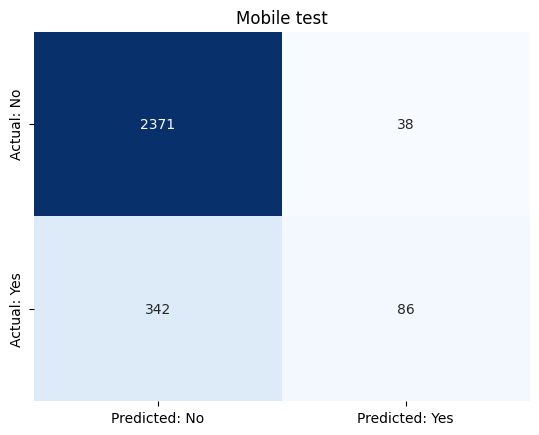

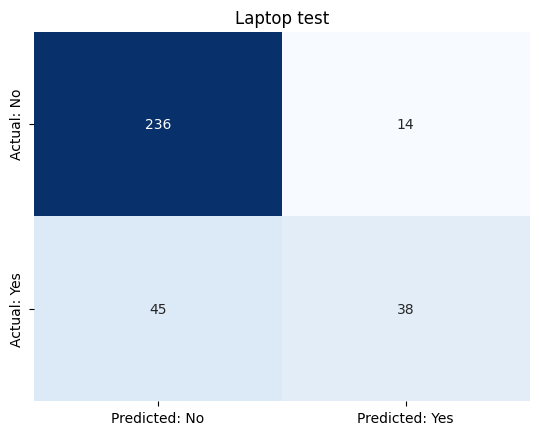

In [97]:
from sklearn.metrics import confusion_matrix

def show_cm(model, X, y, name, threshold=0.5):
    pred = (model.predict(X) >= threshold).astype(int)
    cm = pd.DataFrame(confusion_matrix(y, pred),
                      index=['Actual: No', 'Actual: Yes'],
                      columns=['Predicted: No', 'Predicted: Yes'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(name)
    plt.show()

show_cm(logit_mobile, Xm_test, ym_test, 'Mobile test')
show_cm(logit_laptop, Xl_test, yl_test, 'Laptop test')

In [109]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def scores(model, X, y, threshold=0.5):
    prob = model.predict(X)
    pred = (prob >= threshold).astype(int)
    return {'Accuracy': accuracy_score(y, pred),
            'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred),
            'F1': f1_score(y, pred),
            'ROC-AUC': roc_auc_score(y, prob)}

pd.DataFrame({'Mobile test': scores(logit_mobile, Xm_test, ym_test),
              'Laptop test': scores(logit_laptop, Xl_test, yl_test)}).round(2)

,Mobile test,Laptop test
Accuracy,0.87,0.82
Precision,0.69,0.73
Recall,0.20,0.46
F1,0.31,0.56
ROC-AUC,0.78,0.83


In [99]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_table(X):
    return pd.DataFrame({
        'Variable': X.columns,
        'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    }).sort_values('VIF', ascending=False).round(2)

print('===== Mobile')
print(vif_table(Xm_train))
print('===== Laptop')
print(vif_table(Xl_train))

===== Mobile
                                        Variable   VIF
11        Daily_Avg_mins_spend_on_traveling_page  2.95
6   total_likes_on_outofstation_checkin_received  2.25
14             preferred_location_type_Financial  1.81
1                 Yearly_avg_view_on_travel_page  1.77
8             montly_avg_comment_on_company_page  1.76
17               preferred_location_type_Medical  1.66
16       preferred_location_type_Historical site  1.50
23                              working_flag_Yes  1.34
19          preferred_location_type_Social media  1.28
13         preferred_location_type_Entertainment  1.24
18                 preferred_location_type_Other  1.24
12            preferred_location_type_Big Cities  1.22
21              preferred_location_type_Trekking  1.17
7             week_since_last_outstation_checkin  1.15
4                               member_in_family  1.06
5              Yearly_avg_comment_on_travel_page  1.06
20       preferred_location_type_Tour and Travel  1.

In [106]:
print(logit_mobile.summary())
print(logit_laptop.summary())

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 6619
Model:                          Logit   Df Residuals:                     6595
Method:                           MLE   Df Model:                           23
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.2007
Time:                        08:38:48   Log-Likelihood:                -2246.1
converged:                       True   LL-Null:                       -2810.3
Covariance Type:            nonrobust   LLR p-value:                6.442e-224
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                            0.0769      0.320      0.240      0.810      -0.551       0.705
Yearly_avg_view_on_travel_pag

In [113]:
drop_list = ['member_in_family']

Xm_train2 = Xm_train.drop(columns=drop_list)
Xm_test2 = Xm_test.drop(columns=drop_list)

logit_mobile2 = sm.Logit(ym_train, Xm_train2).fit()


drop_list = ['member_in_family']

Xl_train2 = Xl_train.drop(columns=drop_list)
Xl_test2 = Xl_test.drop(columns=drop_list)

logit_laptop2 = sm.Logit(yl_train, Xl_train2).fit()

pd.DataFrame({'Mobile test': scores(logit_mobile2, Xm_test2, ym_test),
              'Laptop test': scores(logit_laptop2, Xl_test2, yl_test)}).round(2)


Optimization terminated successfully.
         Current function value: 0.339344
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.382042
         Iterations 7


,Mobile test,Laptop test
Accuracy,0.87,0.82
Precision,0.69,0.74
Recall,0.20,0.45
F1,0.31,0.56
ROC-AUC,0.78,0.83


In [114]:
print(logit_mobile2.summary())
print(logit_laptop2.summary())

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 6619
Model:                          Logit   Df Residuals:                     6596
Method:                           MLE   Df Model:                           22
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.2007
Time:                        09:19:02   Log-Likelihood:                -2246.1
converged:                       True   LL-Null:                       -2810.3
Covariance Type:            nonrobust   LLR p-value:                8.896e-225
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                            0.0732      0.312      0.235      0.815      -0.538       0.685
Yearly_avg_view_on_travel_pag

In [116]:
drop_list = ['working_flag_Yes']

Xm_train3 = Xm_train2.drop(columns=drop_list)
Xm_test3 = Xm_test2.drop(columns=drop_list)
logit_mobile3 = sm.Logit(ym_train, Xm_train3).fit()

Xl_train3 = Xl_train2.drop(columns=drop_list)
Xl_test3 = Xl_test2.drop(columns=drop_list)
logit_laptop3 = sm.Logit(yl_train, Xl_train3).fit()

pd.DataFrame({'Mobile': scores(logit_mobile3, Xm_test3, ym_test),
              'Laptop': scores(logit_laptop3, Xl_test3, yl_test)}).round(2)


Optimization terminated successfully.
         Current function value: 0.339367
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.382052
         Iterations 7


,Mobile,Laptop
Accuracy,0.87,0.82
Precision,0.70,0.72
Recall,0.20,0.46
F1,0.31,0.56
ROC-AUC,0.78,0.83


In [117]:
print(logit_mobile3.summary())
print(logit_laptop3.summary())

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 6619
Model:                          Logit   Df Residuals:                     6597
Method:                           MLE   Df Model:                           21
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.2007
Time:                        09:29:22   Log-Likelihood:                -2246.3
converged:                       True   LL-Null:                       -2810.3
Covariance Type:            nonrobust   LLR p-value:                1.392e-225
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                            0.0374      0.305      0.122      0.903      -0.561       0.636
Yearly_avg_view_on_travel_pag

In [118]:
drop_m = ['Yearly_avg_comment_on_travel_page']
drop_l = ['montly_avg_comment_on_company_page']

Xm_train4 = Xm_train3.drop(columns=drop_m)
Xm_test4 = Xm_test3.drop(columns=drop_m)
logit_mobile4 = sm.Logit(ym_train, Xm_train4).fit()

Xl_train4 = Xl_train3.drop(columns=drop_l)
Xl_test4 = Xl_test3.drop(columns=drop_l)
logit_laptop4 = sm.Logit(yl_train, Xl_train4).fit()

pd.DataFrame({'Mobile before': scores(logit_mobile3, Xm_test3, ym_test),
              'Mobile after': scores(logit_mobile4, Xm_test4, ym_test),
              'Laptop before': scores(logit_laptop3, Xl_test3, yl_test),
              'Laptop after': scores(logit_laptop4, Xl_test4, yl_test)}).round(2)


Optimization terminated successfully.
         Current function value: 0.339394
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.382245
         Iterations 7


,Mobile before,Mobile after,Laptop before,Laptop after
Accuracy,0.87,0.87,0.82,0.82
Precision,0.70,0.70,0.72,0.73
Recall,0.20,0.20,0.46,0.46
F1,0.31,0.31,0.56,0.56
ROC-AUC,0.78,0.78,0.83,0.83


In [119]:
print(logit_mobile4.summary())
print(logit_laptop4.summary())

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 6619
Model:                          Logit   Df Residuals:                     6598
Method:                           MLE   Df Model:                           20
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.2006
Time:                        09:33:49   Log-Likelihood:                -2246.5
converged:                       True   LL-Null:                       -2810.3
Covariance Type:            nonrobust   LLR p-value:                2.180e-226
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                           -0.0364      0.279     -0.131      0.896      -0.583       0.511
Yearly_avg_view_on_travel_pag

In [123]:
drop_m = ['montly_avg_comment_on_company_page']

Xm_train5 = Xm_train4.drop(columns=drop_m)
Xm_test5 = Xm_test4.drop(columns=drop_m)
logit_mobile5 = sm.Logit(ym_train, Xm_train5).fit()

pd.DataFrame({'Mobile after': scores(logit_mobile5, Xm_test5, ym_test)}).round(2)



Optimization terminated successfully.
         Current function value: 0.339473
         Iterations 7


,Mobile after
Accuracy,0.87
Precision,0.70
Recall,0.21
F1,0.32
ROC-AUC,0.78


In [126]:
print(logit_mobile5.summary())
print(logit_laptop4.summary())

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 6619
Model:                          Logit   Df Residuals:                     6599
Method:                           MLE   Df Model:                           19
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.2004
Time:                        12:00:46   Log-Likelihood:                -2247.0
converged:                       True   LL-Null:                       -2810.3
Covariance Type:            nonrobust   LLR p-value:                4.644e-227
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                           -0.2027      0.226     -0.897      0.370      -0.645       0.240
Yearly_avg_view_on_travel_pag

In [127]:
Xm_test_final = Xm_test[logit_mobile5.params.index]
Xl_test_final = Xl_test[logit_laptop4.params.index]

pd.DataFrame({'Mobile test': scores(logit_mobile5, Xm_test_final, ym_test),
              'Laptop test': scores(logit_laptop4, Xl_test_final, yl_test)}).round(3)

,Mobile test,Laptop test
Accuracy,0.867,0.823
Precision,0.704,0.731
Recall,0.206,0.458
F1,0.318,0.563
ROC-AUC,0.781,0.835


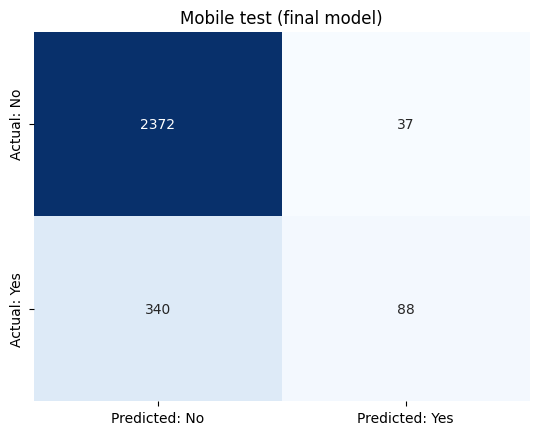

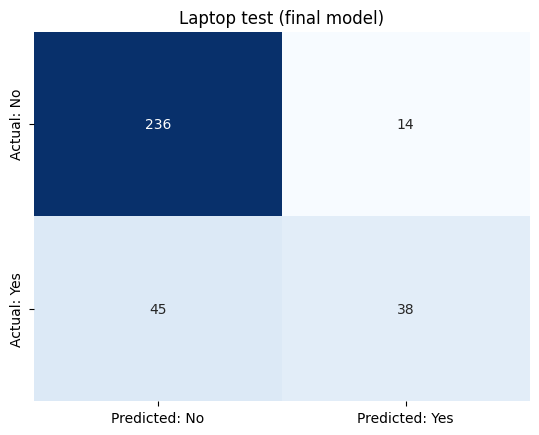

In [128]:
show_cm(logit_mobile5, Xm_test_final, ym_test, 'Mobile test (final model)')
show_cm(logit_laptop4, Xl_test_final, yl_test, 'Laptop test (final model)')

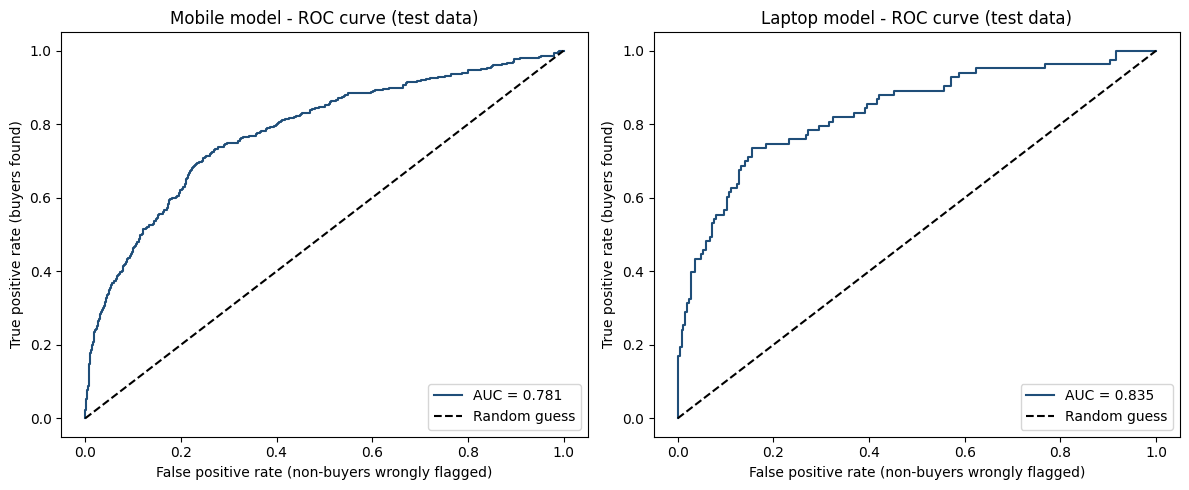

In [129]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model, X, y) in zip(axes, [
        ('Mobile', logit_mobile5, Xm_test_final, ym_test),
        ('Laptop', logit_laptop4, Xl_test_final, yl_test)]):
    prob = model.predict(X)
    fpr, tpr, _ = roc_curve(y, prob)
    ax.plot(fpr, tpr, color='#1f4e79', label='AUC = %.3f' % roc_auc_score(y, prob))
    ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
    ax.set_xlabel('False positive rate (non-buyers wrongly flagged)')
    ax.set_ylabel('True positive rate (buyers found)')
    ax.set_title(name + ' model - ROC curve (test data)')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [131]:
print('-------mobile-------')
print(logit_mobile5.params)
print('-------laptop-------')
print(logit_laptop4.params)

-------mobile-------
const                                          -0.202655
Yearly_avg_view_on_travel_page                 -0.003424
total_likes_on_outstation_checkin_given        -0.000009
yearly_avg_Outstation_checkins                  0.030685
total_likes_on_outofstation_checkin_received   -0.000088
week_since_last_outstation_checkin              0.146811
travelling_network_rating                      -0.219843
Adult_flag                                     -1.269715
Daily_Avg_mins_spend_on_traveling_page         -0.033063
preferred_location_type_Big Cities              0.827152
preferred_location_type_Entertainment           1.233852
preferred_location_type_Financial               0.351667
preferred_location_type_Hill Stations           0.999750
preferred_location_type_Historical site         0.160923
preferred_location_type_Medical                 0.282724
preferred_location_type_Other                  -0.234500
preferred_location_type_Social media            0.900392
preferred_

In [132]:
def odds_table(model):
    odds = np.exp(model.params)
    return pd.DataFrame({'Odds ratio': odds,
                         'Change in odds (%)': (odds - 1) * 100,
                         'p-value': model.pvalues}).drop('const').round(3)

print('-------mobile-------')
print(odds_table(logit_mobile5))
print('-------laptop-------')
print(odds_table(logit_laptop4))

-------mobile-------
                                              Odds ratio  Change in odds (%)  \
Yearly_avg_view_on_travel_page                     0.997              -0.342   
total_likes_on_outstation_checkin_given            1.000              -0.001   
yearly_avg_Outstation_checkins                     1.031               3.116   
total_likes_on_outofstation_checkin_received       1.000              -0.009   
week_since_last_outstation_checkin                 1.158              15.814   
travelling_network_rating                          0.803             -19.735   
Adult_flag                                         0.281             -71.909   
Daily_Avg_mins_spend_on_traveling_page             0.967              -3.252   
preferred_location_type_Big Cities                 2.287             128.680   
preferred_location_type_Entertainment              3.434             243.443   
preferred_location_type_Financial                  1.421              42.144   
preferred_location_

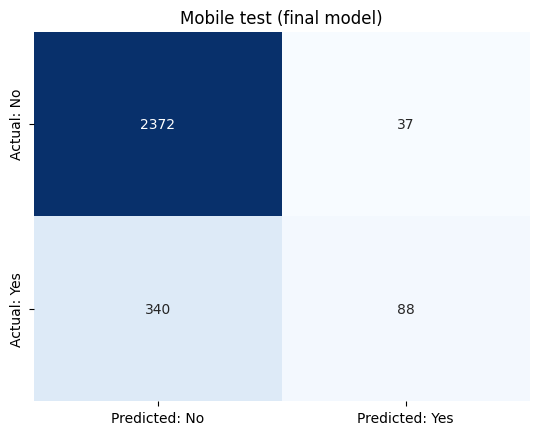

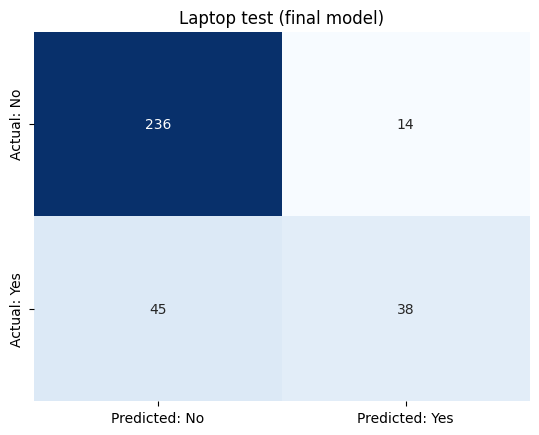

In [133]:
show_cm(logit_mobile5, Xm_test_final, ym_test, 'Mobile test (final model)')
show_cm(logit_laptop4, Xl_test_final, yl_test, 'Laptop test (final model)')